# Xor Testi

In [1]:
%cd /Users/aysekaragoz/Desktop/yapay_sinir_agi/neural-net-numpy

/Users/aysekaragoz/Desktop/yapay_sinir_agi/neural-net-numpy


In [2]:
import numpy as np

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

In [3]:
from src.layers import Dense
from src.activations import Sigmoid,ReLU
from src.network import Network
from src.losses import mse,mse_deriv
import src.optimizer as optimizer
from src.__init__ import train
layers = [
    Dense(2, 4),
    ReLU(),
    Dense(4, 1),
    Sigmoid()
]

network = Network(layers, mse, mse_deriv)

In [4]:
optimizer1 = optimizer.SGD()
history = train(
    network,
    X,
    y,
    optimizer1,
    epochs=5000,
    batch_size=4
)

y_pred = network.forward(X)

print("Gerçek değerler:")
print(y.ravel())

print("Tahminler:")
print(y_pred.ravel())

print("İkili tahminler:")
print((y_pred > 0.5).astype(int).ravel())

print("Son loss:", history[-1])

Epoch 15: Loss = 0.297857
Epoch 30: Loss = 0.247563
Epoch 45: Loss = 0.218425
Epoch 60: Loss = 0.198742
Epoch 75: Loss = 0.189322
Epoch 90: Loss = 0.180109
Epoch 105: Loss = 0.172467
Epoch 120: Loss = 0.165252
Epoch 135: Loss = 0.158389
Epoch 150: Loss = 0.152486
Epoch 165: Loss = 0.146991
Epoch 180: Loss = 0.141071
Epoch 195: Loss = 0.136106
Epoch 210: Loss = 0.130996
Epoch 225: Loss = 0.126099
Epoch 240: Loss = 0.121333
Epoch 255: Loss = 0.116664
Epoch 270: Loss = 0.112076
Epoch 285: Loss = 0.107622
Epoch 300: Loss = 0.103495
Epoch 315: Loss = 0.099219
Epoch 330: Loss = 0.095482
Epoch 345: Loss = 0.091896
Epoch 360: Loss = 0.087845
Epoch 375: Loss = 0.084025
Epoch 390: Loss = 0.080519
Epoch 405: Loss = 0.077096
Epoch 420: Loss = 0.073702
Epoch 435: Loss = 0.070407
Epoch 450: Loss = 0.067210
Epoch 465: Loss = 0.064221
Epoch 480: Loss = 0.061500
Epoch 495: Loss = 0.058857
Epoch 510: Loss = 0.056172
Epoch 525: Loss = 0.053881
Epoch 540: Loss = 0.051460
Epoch 555: Loss = 0.049255
Epoch 5

# Makemoons Deneyi

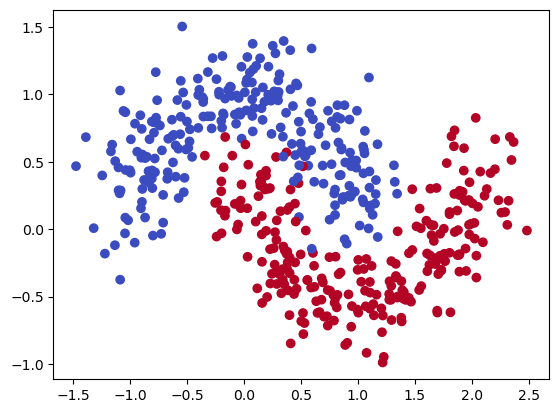

X shape: (500, 2)
y shape: (500, 1)


In [5]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

y = y.reshape(-1, 1)

plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm")
plt.show()

print("X shape:", X.shape)
print("y shape:", y.shape)

In [6]:
layers = [
    Dense(2, 4),
    ReLU(),
    Dense(4, 1),
    Sigmoid()
]

network = Network(layers, mse, mse_deriv)
optimizer2=optimizer.Momentum()
history = train(
    network,
    X,
    y,
    optimizer2,
    epochs=5000,
    batch_size=4
)

y_pred = network.forward(X)

print("Gerçek değerler:")
print(y.ravel())

print("Tahminler:")
print(y_pred.ravel())

print("İkili tahminler:")
print((y_pred > 0.5).astype(int).ravel())

print("Son loss:", history[-1])

Epoch 15: Loss = 0.134907
Epoch 30: Loss = 0.105062
Epoch 45: Loss = 0.097023
Epoch 60: Loss = 0.092704
Epoch 75: Loss = 0.089602
Epoch 90: Loss = 0.087098
Epoch 105: Loss = 0.085419
Epoch 120: Loss = 0.084276
Epoch 135: Loss = 0.083456
Epoch 150: Loss = 0.082765
Epoch 165: Loss = 0.082156
Epoch 180: Loss = 0.081580
Epoch 195: Loss = 0.081101
Epoch 210: Loss = 0.080675
Epoch 225: Loss = 0.080313
Epoch 240: Loss = 0.080016
Epoch 255: Loss = 0.079727
Epoch 270: Loss = 0.079491
Epoch 285: Loss = 0.079283
Epoch 300: Loss = 0.079074
Epoch 315: Loss = 0.078874
Epoch 330: Loss = 0.078720
Epoch 345: Loss = 0.078587
Epoch 360: Loss = 0.078429
Epoch 375: Loss = 0.078308
Epoch 390: Loss = 0.078176
Epoch 405: Loss = 0.078108
Epoch 420: Loss = 0.078008
Epoch 435: Loss = 0.077932
Epoch 450: Loss = 0.077833
Epoch 465: Loss = 0.077747
Epoch 480: Loss = 0.077674
Epoch 495: Loss = 0.077625
Epoch 510: Loss = 0.077567
Epoch 525: Loss = 0.077510
Epoch 540: Loss = 0.077470
Epoch 555: Loss = 0.077425
Epoch 5

In [7]:
y_pred = network.forward(X)
predictions = (y_pred > 0.5).astype(int)
accuracy = np.mean(predictions == y)

print("Accuracy:", accuracy)

Accuracy: 0.89


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y.ravel()
)

In [9]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Kendi ağın: eğitim
layers = [
    Dense(2, 4),
    ReLU(),
    Dense(4, 1),
    Sigmoid()
]

network = Network(layers, mse, mse_deriv)

history = train(
    network,
    X_train,
    y_train,
    optimizer.SGD(lr=0.1),
    epochs=1000,
    batch_size=16
)

# Kendi ağının test başarısı
my_pred = (network.forward(X_test) > 0.5).astype(int)
my_accuracy = accuracy_score(y_test, my_pred)

# Scikit-learn modeli
sk_model = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.1,
    max_iter=1000,
    random_state=42
)

sk_model.fit(X_train, y_train.ravel())
sk_pred = sk_model.predict(X_test)
sk_accuracy = accuracy_score(y_test.ravel(), sk_pred)

print(f"Kendi ağımızın accuracy: {my_accuracy:.4f}")
print(f"Scikit-learn accuracy:   {sk_accuracy:.4f}")
print(f"Fark:                    {abs(my_accuracy - sk_accuracy):.4f}")

Epoch 15: Loss = 0.087053
Epoch 30: Loss = 0.085015
Epoch 45: Loss = 0.083905
Epoch 60: Loss = 0.082660
Epoch 75: Loss = 0.081625
Epoch 90: Loss = 0.080979
Epoch 105: Loss = 0.080447
Epoch 120: Loss = 0.079631
Epoch 135: Loss = 0.079246
Epoch 150: Loss = 0.078635
Epoch 165: Loss = 0.078369
Epoch 180: Loss = 0.078432
Epoch 195: Loss = 0.078020
Epoch 210: Loss = 0.077913
Epoch 225: Loss = 0.077647
Epoch 240: Loss = 0.077416
Epoch 255: Loss = 0.077483
Epoch 270: Loss = 0.077306
Epoch 285: Loss = 0.077210
Epoch 300: Loss = 0.077082
Epoch 315: Loss = 0.077029
Epoch 330: Loss = 0.076930
Epoch 345: Loss = 0.077018
Epoch 360: Loss = 0.077099
Epoch 375: Loss = 0.076885
Epoch 390: Loss = 0.076931
Epoch 405: Loss = 0.076655
Epoch 420: Loss = 0.077025
Epoch 435: Loss = 0.076795
Epoch 450: Loss = 0.076724
Epoch 465: Loss = 0.076694
Epoch 480: Loss = 0.076560
Epoch 495: Loss = 0.076615
Epoch 510: Loss = 0.076485
Epoch 525: Loss = 0.076517
Epoch 540: Loss = 0.076370
Epoch 555: Loss = 0.076517
Epoch 5

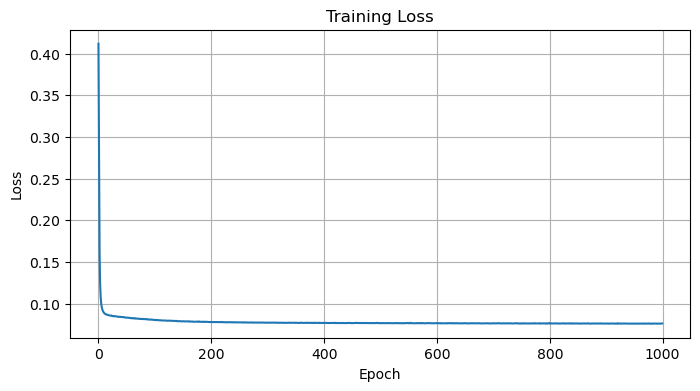

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

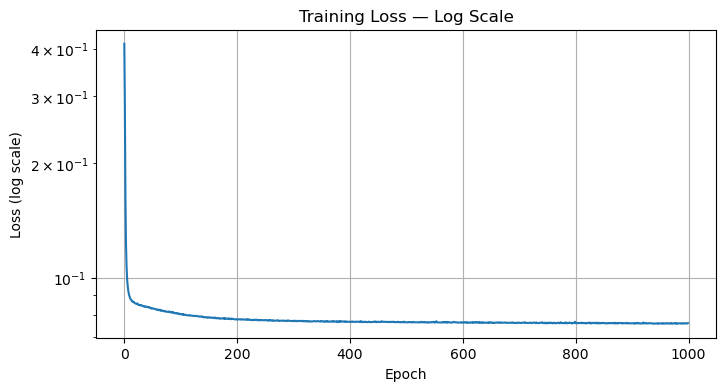

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss (log scale)")
plt.title("Training Loss — Log Scale")
plt.grid(True)
plt.show()

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def plot_decision_boundary(network, X, y, ax=None, title="Decision Boundary"):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = network.forward(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        levels=[0, 0.5, 1],
        alpha=0.3,
        cmap="coolwarm"
    )
    ax.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1.5)
    ax.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", edgecolors="k")
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

    return ax

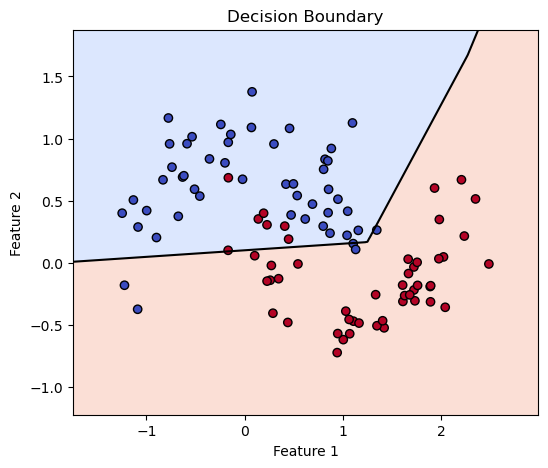

In [13]:
plot_decision_boundary(network, X_test, y_test)
plt.show()

Epoch 15: Loss = 0.107371
Epoch 30: Loss = 0.096949
Epoch 45: Loss = 0.093900
Epoch 60: Loss = 0.092445
Epoch 75: Loss = 0.091542
Epoch 90: Loss = 0.091268
Epoch 105: Loss = 0.091060
Epoch 120: Loss = 0.091130
Epoch 135: Loss = 0.090909
Epoch 150: Loss = 0.090831
Epoch 165: Loss = 0.090687
Epoch 180: Loss = 0.090641
Epoch 195: Loss = 0.090707
Epoch 210: Loss = 0.090640
Epoch 225: Loss = 0.090852
Epoch 240: Loss = 0.090686
Epoch 255: Loss = 0.090502
Epoch 270: Loss = 0.090533
Epoch 285: Loss = 0.090689
Epoch 300: Loss = 0.090767
Epoch 315: Loss = 0.090759
Epoch 330: Loss = 0.090569
Epoch 345: Loss = 0.090520
Epoch 360: Loss = 0.090674
Epoch 375: Loss = 0.090594
Epoch 390: Loss = 0.090646
Epoch 405: Loss = 0.090482
Epoch 420: Loss = 0.090381
Epoch 435: Loss = 0.090529
Epoch 450: Loss = 0.090747
Epoch 465: Loss = 0.090433
Epoch 480: Loss = 0.090502
Epoch 495: Loss = 0.090613
Epoch 510: Loss = 0.090608
Epoch 525: Loss = 0.090260
Epoch 540: Loss = 0.090344
Epoch 555: Loss = 0.090355
Epoch 5

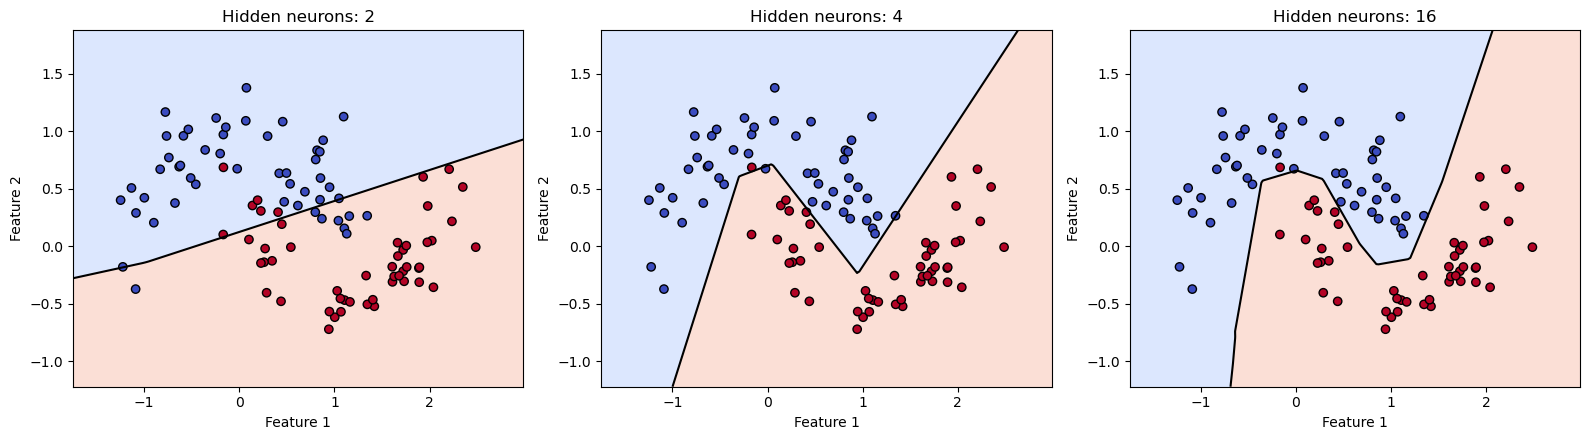

In [14]:
hidden_sizes = [2, 4, 16]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for size, ax in zip(hidden_sizes, axes):
    layers = [
        Dense(2, size),
        ReLU(),
        Dense(size, 1),
        Sigmoid()
    ]

    model = Network(layers, mse, mse_deriv)

    history = train(
        model,
        X_train,
        y_train,
        optimizer.SGD(lr=0.1),
        epochs=1000,
        batch_size=16
    )

    plot_decision_boundary(
        model, X_test, y_test,
        ax=ax,
        title=f"Hidden neurons: {size}"
    )

plt.tight_layout()
plt.show()

In [15]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Sınıf etiketlerini one-hot biçimine çevir
y_train_onehot = np.eye(3)[y_train]
y_test_onehot = np.eye(3)[y_test]

print("X_train:", X_train.shape)
print("y_train:", y_train_onehot.shape)
print("Sınıflar:", iris.target_names)

X_train: (120, 4)
y_train: (120, 3)
Sınıflar: ['setosa' 'versicolor' 'virginica']


In [16]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train = np.eye(3)[y_train]
y_test_onehot = np.eye(3)[y_test]

print(X_train.shape)  # (120, 4)
print(y_train.shape)  # (120, 3)

(120, 4)
(120, 3)


In [17]:
from src.layers import Dense
from src.activations import ReLU, Softmax
from src.network import Network
from src.losses import categorical_cross_entropy, categorical_cross_entropy_deriv
import src.optimizer

layers = [
    Dense(4, 8),
    ReLU(),
    Dense(8, 3),
    Softmax()
]

network = Network(
    layers,
    categorical_cross_entropy,
    categorical_cross_entropy_deriv
)

history = train(
    network,
    X_train,
    y_train,
    src.optimizer.SGD(lr=0.05),
    epochs=1000,
    batch_size=16
)

Epoch 15: Loss = 0.345787
Epoch 30: Loss = 0.198335
Epoch 45: Loss = 0.133022
Epoch 60: Loss = 0.102456
Epoch 75: Loss = 0.086858
Epoch 90: Loss = 0.076732
Epoch 105: Loss = 0.070655
Epoch 120: Loss = 0.064916
Epoch 135: Loss = 0.061706
Epoch 150: Loss = 0.058251
Epoch 165: Loss = 0.056030
Epoch 180: Loss = 0.054042
Epoch 195: Loss = 0.054688
Epoch 210: Loss = 0.051213
Epoch 225: Loss = 0.051927
Epoch 240: Loss = 0.049079
Epoch 255: Loss = 0.048560
Epoch 270: Loss = 0.049188
Epoch 285: Loss = 0.048629
Epoch 300: Loss = 0.047203
Epoch 315: Loss = 0.046690
Epoch 330: Loss = 0.047094
Epoch 345: Loss = 0.044094
Epoch 360: Loss = 0.045704
Epoch 375: Loss = 0.043246
Epoch 390: Loss = 0.044531
Epoch 405: Loss = 0.044358
Epoch 420: Loss = 0.042689
Epoch 435: Loss = 0.041981
Epoch 450: Loss = 0.042419
Epoch 465: Loss = 0.042584
Epoch 480: Loss = 0.042050
Epoch 495: Loss = 0.041284
Epoch 510: Loss = 0.041033
Epoch 525: Loss = 0.041428
Epoch 540: Loss = 0.040371
Epoch 555: Loss = 0.041747
Epoch 5